# PRIM — Ambulance Pooling (fac=0, amb=1)

Find where T1 mortality > 0.


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster/20260605_212356_scenario_2btg_pooling_limit_baseline_stove/results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

UNCERTAINTIES = ["ccp_r1_same_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

sub = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].reset_index(drop=True)
print(f"Policy: Ambulance Pooling (fac=0, amb=1), {len(sub)} runs")
print(f"T1 mortality range: {sub['death_rate_T1_BCAS'].min():.4f} - {sub['death_rate_T1_BCAS'].max():.4f}")
print(f"Nonzero: {(sub['death_rate_T1_BCAS'] > 0).sum()} / {len(sub)} ({(sub['death_rate_T1_BCAS'] > 0).mean():.1%})")


Loaded 40960 runs
Policy: Ambulance Pooling (fac=0, amb=1), 10240 runs
T1 mortality range: 0.0000 - 1.0000
Nonzero: 5512 / 10240 (53.8%)


## PRIM — Where does T1 mortality occur?


Cases of interest: 5512 / 10240 (53.8%)



Selected box:
coverage      0.154209
density       0.998825
id           27.000000
k           850.000000
mass          0.083105
mean          0.998825
n           851.000000
res_dim       3.000000
Name: 27, dtype: float64

                     box 27                                       
                        min        max      qp value      qp value
waves_per_day      1.000000   1.500000           NaN  1.064507e-79
wave_duration_min  1.000000  44.500000           NaN  2.515727e-09
bcas_rate          0.029256   0.069998  1.577767e-81           NaN



[None]

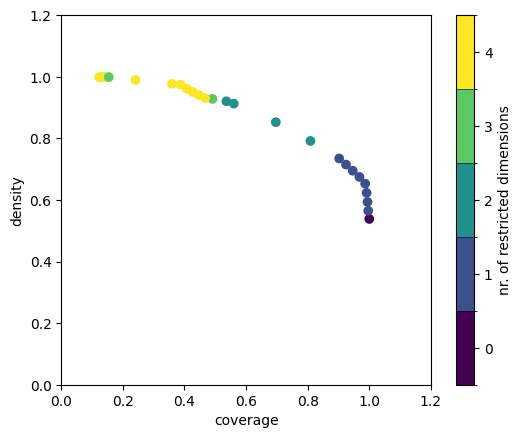

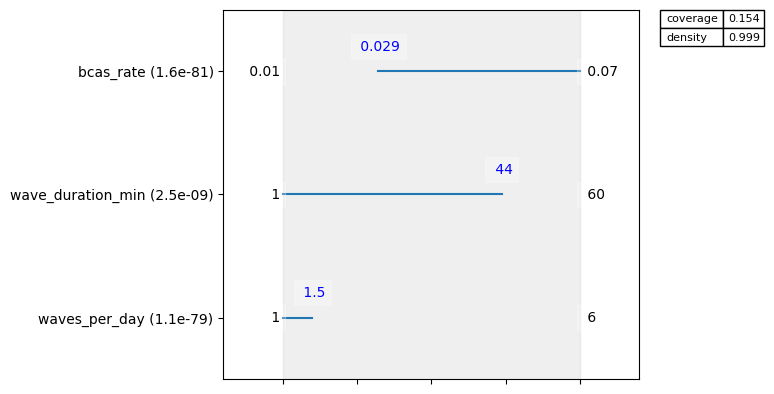

In [2]:
from ema_workbench.analysis import prim

x = sub[UNCERTAINTIES].astype(float)
y = sub["death_rate_T1_BCAS"].values > 0

print(f"Cases of interest: {y.sum()} / {len(y)} ({y.mean():.1%})")

p = prim.Prim(x, y, threshold=0.5)
box = p.find_box()
box.show_tradeoff()
print("\nSelected box:")
box.inspect(style="graph")
box.inspect()
